In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Users\DIVYAM UPADHYAY\Desktop\indian-startup-funding-analysis\data\Raw\startup_funding.csv")
df.head()

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN


In [2]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Sr No              3044 non-null   int64
 1   Date dd/mm/yyyy    3044 non-null   str  
 2   Startup Name       3044 non-null   str  
 3   Industry Vertical  2873 non-null   str  
 4   SubVertical        2108 non-null   str  
 5   City  Location     2864 non-null   str  
 6   Investors Name     3020 non-null   str  
 7   InvestmentnType    3040 non-null   str  
 8   Amount in USD      2084 non-null   str  
 9   Remarks            419 non-null    str  
dtypes: int64(1), str(9)
memory usage: 593.3 KB


(3044, 10)

## Stage 1: Data Overview & Quality Issues Found
- 3044 rows, 10 columns
- Date and Amount in USD are stored as text, not proper types
- Amount in USD uses Indian numbering (lakh/crore commas), plus "undisclosed" placeholder values
- City Location has duplicate/inconsistent naming (Bengaluru/Bangalore, Gurgaon/Gurugram) and multi-city entries
- SubVertical (936 missing) and Remarks (2625 missing) are too sparse to be reliable 

In [3]:
df['Date dd/mm/yyyy'] = pd.to_datetime(df['Date dd/mm/yyyy'], format='%d/%m/%Y', errors='coerce')
df['Date dd/mm/yyyy'].head()

0   2020-01-09
1   2020-01-13
2   2020-01-09
3   2020-01-02
4   2020-01-02
Name: Date dd/mm/yyyy, dtype: datetime64[us]

In [4]:
df['Date dd/mm/yyyy'].isna().sum()

np.int64(8)

In [5]:
df[df['Date dd/mm/yyyy'].isna()]

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
192,193,NaT,Loan Tap,Consumer Internet,Online Lending Platform For Salaried Professio...,Mumbai,"Shunwei Capital, Tuscan Ventures, Ashish Goenk...",Private Equity,"62,50,000",NaN
2571,2572,NaT,HandyHome,Hyperlocal Electronics repair Service,NaN,Mumbai,"Bessemer Ventures, Kae Capital",Seed Funding,"6,30,000",NaN
2606,2607,NaT,\\xc2\\xa0Infinity Assurance,\\xc2\\xa0Warranty Programs Service Administra...,NaN,\\xc2\\xa0New Delhi,\\xc2\\xa0Indian Angel Network,Seed Funding,"\\xc2\\xa0600,000",NaN
2775,2776,NaT,Mobiefit,Mobile Fitness App,NaN,Goa,Prototyze,Seed Funding,NaN,NaN
2776,2777,NaT,Plancess,Online Education Platform,NaN,Mumbai,"Rajendra Gogri,\\xc2\\xa0 Chandrakant Gogri",Seed Funding,"20,00,000",NaN
2831,2832,NaT,The Porter,Logistics Tech,NaN,Mumbai,Kae Capital,Seed Funding,"5,00,000",NaN
3011,3012,NaT,Wishberry,NaN,NaN,NaN,"Rajan Anandan, Shankar Mahadevan, Deep Kalra &...",Seed Funding,"6,50,000",NaN
3029,3030,NaT,Corporate360,NaN,NaN,NaN,Group of Angel Investors,Seed Funding,"2,00,000",NaN


In [6]:
df[df['Date dd/mm/yyyy'].isna()][['Sr No', 'Startup Name']]

,Sr No,Startup Name
192,193,Loan Tap
2571,2572,HandyHome
2606,2607,\\xc2\\xa0Infinity Assurance
2775,2776,Mobiefit
2776,2777,Plancess
2831,2832,The Porter
3011,3012,Wishberry
3029,3030,Corporate360


In [7]:
# Re-load fresh so we still have the original raw date text
df = pd.read_csv(r"C:\Users\DIVYAM UPADHYAY\Desktop\indian-startup-funding-analysis\data\Raw\startup_funding.csv")

# Manual fixes for the 8 broken date rows, keyed by Sr No
date_fixes = {
    193: '05/07/2018',
    2572: '01/07/2015',
    2607: '10/07/2015',
    2776: '12/05/2015',
    2777: '12/05/2015',
    2832: '13/04/2015',
    3012: '15/01/2015',
    3030: '22/01/2015'
}

for sr_no, correct_date in date_fixes.items():
    df.loc[df['Sr No'] == sr_no, 'Date dd/mm/yyyy'] = correct_date

# Also strip any hidden whitespace/unicode characters from the whole column, just in case others exist
df['Date dd/mm/yyyy'] = df['Date dd/mm/yyyy'].str.strip()

# Now convert to datetime again
df['Date dd/mm/yyyy'] = pd.to_datetime(df['Date dd/mm/yyyy'], format='%d/%m/%Y', errors='coerce')

df['Date dd/mm/yyyy'].isna().sum()

np.int64(0)

In [8]:
# Step 1: see all the "non-numeric" junk values before we strip them
df['Amount in USD'].dropna().str.strip().loc[~df['Amount in USD'].dropna().str.replace(',', '').str.strip().str.isdigit()].unique()

<ArrowStringArray>
[         'undisclosed',              'unknown',          'Undisclosed',
         '48,89,975.54',         '27,39,034.68',       '1,51,09,500.00',
          '14,342,000+', '\\xc2\\xa020,000,000', '\\xc2\\xa016,200,000',
        '\\xc2\\xa0N/A',    '\\xc2\\xa0600,000',    '\\xc2\\xa0685,000',
 '\\xc2\\xa019,350,000',  '\\xc2\\xa05,000,000', '\\xc2\\xa010,000,000']
Length: 15, dtype: str

In [9]:
# Step A: strip hidden whitespace/unicode characters from the whole column
df['Amount in USD'] = df['Amount in USD'].str.strip()

# Step B: standardize placeholder/unknown text to NaN
placeholder_values = ['undisclosed', 'Undisclosed', 'unknown', 'N/A']
df.loc[df['Amount in USD'].isin(placeholder_values), 'Amount in USD'] = np.nan

# Step C: remove trailing '+' signs
df['Amount in USD'] = df['Amount in USD'].str.replace('+', '', regex=False)

# Step D: remove commas, then convert to numeric (float handles the decimal cases)
df['Amount in USD'] = df['Amount in USD'].str.replace(',', '', regex=False)
df['Amount in USD'] = pd.to_numeric(df['Amount in USD'], errors='coerce')

df['Amount in USD'].isna().sum()

np.int64(978)

In [10]:
df['Amount in USD'].describe()

count    2.066000e+03
mean     1.842792e+07
std      1.213441e+08
min      1.600000e+04
25%      4.712500e+05
50%      1.725000e+06
75%      8.000000e+06
max      3.900000e+09
Name: Amount in USD, dtype: float64

In [11]:
df[df['Amount in USD'] == df['Amount in USD'].max()][['Startup Name', 'Date dd/mm/yyyy', 'Amount in USD', 'InvestmentnType']]

,Startup Name,Date dd/mm/yyyy,Amount in USD,InvestmentnType
60,Rapido Bike Taxi,2019-08-27,3.900000e+09,Series B


In [12]:
df.nlargest(10, 'Amount in USD')[['Startup Name', 'Date dd/mm/yyyy', 'Amount in USD']]

,Startup Name,Date dd/mm/yyyy,Amount in USD
60,Rapido Bike Taxi,2019-08-27,3.900000e+09
651,Flipkart,2017-08-11,2.500000e+09
830,Paytm,2017-05-18,1.400000e+09
966,Flipkart,2017-03-21,1.400000e+09
31,Paytm,2019-11-25,1.000000e+09
2648,Flipkart.com,2015-07-28,7.000000e+08
2459,Paytm,2015-09-29,6.800000e+08
188,True North,2018-08-30,6.000000e+08
33,Udaan,2019-10-02,5.850000e+08
2244,Ola,2015-11-18,5.000000e+08


In [13]:
df.loc[df['Startup Name'] == 'Rapido Bike Taxi', 'Amount in USD'] = np.nan

# Re-check the top 10 now
df.nlargest(10, 'Amount in USD')[['Startup Name', 'Date dd/mm/yyyy', 'Amount in USD']]

,Startup Name,Date dd/mm/yyyy,Amount in USD
651,Flipkart,2017-08-11,2.500000e+09
830,Paytm,2017-05-18,1.400000e+09
966,Flipkart,2017-03-21,1.400000e+09
31,Paytm,2019-11-25,1.000000e+09
2648,Flipkart.com,2015-07-28,7.000000e+08
2459,Paytm,2015-09-29,6.800000e+08
188,True North,2018-08-30,6.000000e+08
33,Udaan,2019-10-02,5.850000e+08
2244,Ola,2015-11-18,5.000000e+08
2470,Snapdeal,2015-08-01,5.000000e+08


# Stage 2: Data Cleaning, Fixing the city location column begin from here.

In [14]:
df['City  Location'].value_counts()

City  Location
Bangalore                 700
Mumbai                    567
New Delhi                 421
Gurgaon                   287
Bengaluru                 141
                         ... 
\\xc2\\xa0Noida             1
\\xc2\\xa0Bangalore         1
\\xc2\\xa0Mumbai            1
New Delhi / California      1
Dallas / Hyderabad          1
Name: count, Length: 112, dtype: int64

In [15]:
df.rename(columns={'City  Location': 'City'}, inplace=True)
df['City'].value_counts()

City
Bangalore                 700
Mumbai                    567
New Delhi                 421
Gurgaon                   287
Bengaluru                 141
                         ... 
\\xc2\\xa0Noida             1
\\xc2\\xa0Bangalore         1
\\xc2\\xa0Mumbai            1
New Delhi / California      1
Dallas / Hyderabad          1
Name: count, Length: 112, dtype: int64

In [16]:
# Step A: strip hidden whitespace/unicode characters
df['City'] = df['City'].str.strip()

# Step B: standardize known spelling/rename variants
city_map = {
    'Bangalore': 'Bengaluru',
    'Gurgaon': 'Gurugram',
    'Delhi': 'New Delhi'
}
df['City'] = df['City'].replace(city_map)

df['City'].value_counts()

City
Bengaluru                 841
Mumbai                    567
New Delhi                 455
Gurugram                  337
Pune                      105
                         ... 
\\xc2\\xa0Noida             1
\\xc2\\xa0Bangalore         1
\\xc2\\xa0Mumbai            1
New Delhi / California      1
Dallas / Hyderabad          1
Name: count, Length: 109, dtype: int64

In [17]:
df['City'] = df['City'].str.replace(r'\\xc2\\xa0', '', regex=True)
df['City'] = df['City'].str.strip()  # run again in case any real whitespace remains after removing the junk text
df['City'] = df['City'].replace(city_map)  # re-apply our city_map in case a \xc2\xa0Bangalore now becomes plain Bangalore
df['City'].value_counts()

City
Bengaluru                 841
Mumbai                    567
New Delhi                 455
Gurugram                  337
Pune                      105
                         ... 
\\xc2\\xa0Noida             1
\\xc2\\xa0Bangalore         1
\\xc2\\xa0Mumbai            1
New Delhi / California      1
Dallas / Hyderabad          1
Name: count, Length: 109, dtype: int64

In [18]:
df['City'] = df['City'].str.replace(r'\\\\xc2\\\\xa0', '', regex=True)
df['City'] = df['City'].str.strip()
df['City'] = df['City'].replace(city_map)
df['City'].value_counts()

City
Bengaluru                 842
Mumbai                    568
New Delhi                 458
Gurugram                  341
Pune                      105
                         ... 
New Delhi/ Houston          1
Mumbai / Global             1
India / US                  1
New Delhi / California      1
Dallas / Hyderabad          1
Name: count, Length: 104, dtype: int64

In [19]:
multi_city_mask = df['City'].str.contains('/', na=False)
df[multi_city_mask]['City'].value_counts()

City
Pune / US                 4
Mumbai/Bengaluru          2
India/US                  2
Bangalore/ Bangkok        2
Bangalore / SFO           2
New Delhi / US            2
India/Singapore           1
SFO / Bangalore           1
Seattle / Bangalore       1
Pune/Seattle              1
Pune / Dubai              1
Mumbai / UK               1
Hyderabad/USA             1
Bangalore / Palo Alto     1
Mumbai / NY               1
USA/India                 1
Goa/Hyderabad             1
Noida / Singapore         1
Chennai/ Singapore        1
Pune / Singapore          1
Bangalore / San Mateo     1
New York/ India           1
US/India                  1
Gurgaon / SFO             1
Bangalore / USA           1
New Delhi/ Houston        1
Mumbai / Global           1
India / US                1
New Delhi / California    1
Dallas / Hyderabad        1
Name: count, dtype: int64

In [20]:
# Take the text before the first '/' as the primary city
df['City'] = df['City'].str.split('/').str[0].str.strip()

# Re-apply our city_map one more time, in case a "Bangalore / SFO" became "Bangalore" and needs renaming to Bengaluru
df['City'] = df['City'].replace(city_map)

df['City'].value_counts()

City
Bengaluru    849
Mumbai       573
New Delhi    462
Gurugram     342
Pune         112
            ... 
Varanasi       1
Jodhpur        1
Boston         1
Belgaum        1
Dallas         1
Name: count, Length: 77, dtype: int64

In [21]:
df['City'].isna().sum(), (df['City'] == '').sum()

(np.int64(180), np.int64(0))

In [22]:
df['Industry Vertical'] = df['Industry Vertical'].fillna('Unknown')
df['Investors Name'] = df['Investors Name'].fillna('Unknown')
df['InvestmentnType'] = df['InvestmentnType'].fillna('Unknown')

df.isna().sum()

Sr No                   0
Date dd/mm/yyyy         0
Startup Name            0
Industry Vertical       0
SubVertical           936
City                  180
Investors Name          0
InvestmentnType         0
Amount in USD         979
Remarks              2625
dtype: int64

In [23]:
df['City'] = df['City'].fillna('Unknown')
df.isna().sum()

Sr No                   0
Date dd/mm/yyyy         0
Startup Name            0
Industry Vertical       0
SubVertical           936
City                    0
Investors Name          0
InvestmentnType         0
Amount in USD         979
Remarks              2625
dtype: int64

## Stage 2: Data Cleaning — Summary
- Converted Date to datetime, manually corrected 8 malformed date entries (typos, missing separators, hidden Unicode characters)
- Cleaned Amount in USD: removed commas (Indian numbering), handled 'undisclosed'/'unknown'/'N/A' as NaN, fixed a $3.9B outlier (Rapido) that didn't match real-world funding data
- Standardized City: fixed hidden Unicode characters, merged renamed cities (Bangalore→Bengaluru, Gurgaon→Gurugram), resolved multi-city entries by keeping the first-listed city (~1.25% of rows)
- Filled missing Industry Vertical, Investors Name, InvestmentnType, and City with 'Unknown'
- Dropped SubVertical and Remarks columns (too sparse: 936 and 2625 missing respectively)

## Stage 3: Exploratory Data Analysis (EDA)

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

In [25]:
top_cities = df['City'].value_counts().head(10)
top_cities

City
Bengaluru    849
Mumbai       573
New Delhi    462
Gurugram     342
Unknown      180
Pune         112
Hyderabad    100
Chennai       98
Noida         94
Ahmedabad     38
Name: count, dtype: int64

In [26]:
top_cities = df[df['City'] != 'Unknown']['City'].value_counts().head(10)
top_cities

City
Bengaluru    849
Mumbai       573
New Delhi    462
Gurugram     342
Pune         112
Hyderabad    100
Chennai       98
Noida         94
Ahmedabad     38
Jaipur        30
Name: count, dtype: int64

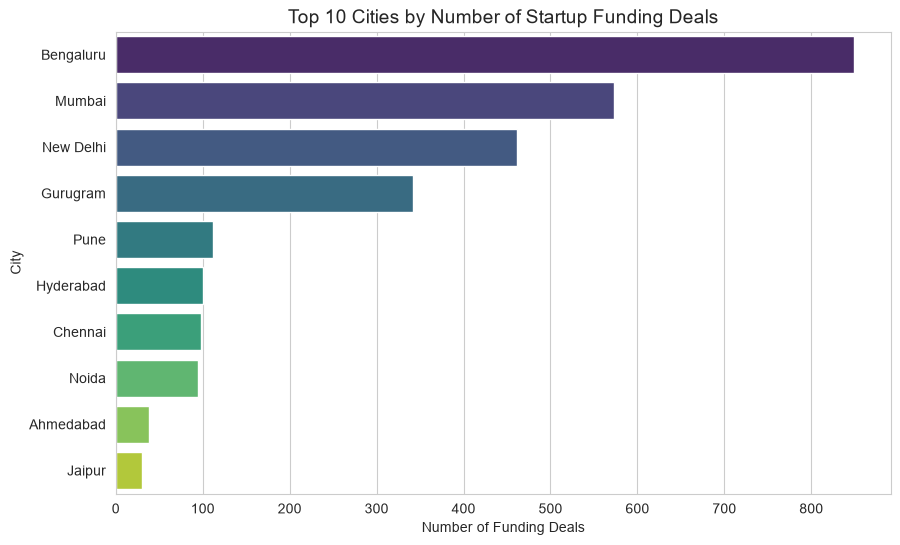

In [27]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_cities.values, y=top_cities.index, hue=top_cities.index, palette='viridis', legend=False)
plt.title('Top 10 Cities by Number of Startup Funding Deals', fontsize=14)
plt.xlabel('Number of Funding Deals')
plt.ylabel('City')
plt.show()

In [28]:
top_cities_amount = df[df['City'] != 'Unknown'].groupby('City')['Amount in USD'].sum().sort_values(ascending=False).head(10)
top_cities_amount

City
Bengaluru     1.461371e+10
Mumbai        4.939225e+09
Gurugram      3.872429e+09
New Delhi     3.358572e+09
Noida         1.263164e+09
Chennai       7.187670e+08
Pune          7.175820e+08
Menlo Park    4.500000e+08
Hyderabad     4.016762e+08
India         3.495000e+08
Name: Amount in USD, dtype: float64

In [29]:
df[df['City'] == 'India'][['Startup Name', 'City', 'Amount in USD']]

,Startup Name,City,Amount in USD
113,Zilingo,India,226000000.0
117,Vyome Therapeutics Inc.,India,22000000.0
141,Engineer.ai,India,29500000.0
142,InCred Finance,India,42000000.0
2594,Axtria,India,30000000.0


In [30]:
df.loc[df['City'] == 'India', 'City'] = 'Unknown'

# Re-run our totals to confirm 'India' is gone and Unknown absorbed these 5 rows
df[df['City'] != 'Unknown'].groupby('City')['Amount in USD'].sum().sort_values(ascending=False).head(10)

City
Bengaluru     1.461371e+10
Mumbai        4.939225e+09
Gurugram      3.872429e+09
New Delhi     3.358572e+09
Noida         1.263164e+09
Chennai       7.187670e+08
Pune          7.175820e+08
Menlo Park    4.500000e+08
Hyderabad     4.016762e+08
California    3.000000e+08
Name: Amount in USD, dtype: float64

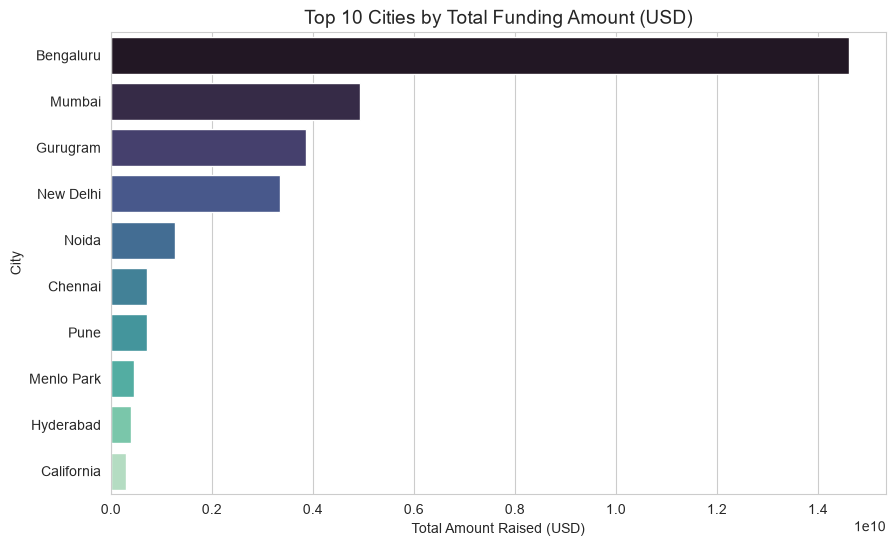

In [31]:
top_cities_amount_plot = df[df['City'] != 'Unknown'].groupby('City')['Amount in USD'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_cities_amount_plot.values, y=top_cities_amount_plot.index, hue=top_cities_amount_plot.index, palette='mako', legend=False)
plt.title('Top 10 Cities by Total Funding Amount (USD)', fontsize=14)
plt.xlabel('Total Amount Raised (USD)')
plt.ylabel('City')
plt.show()

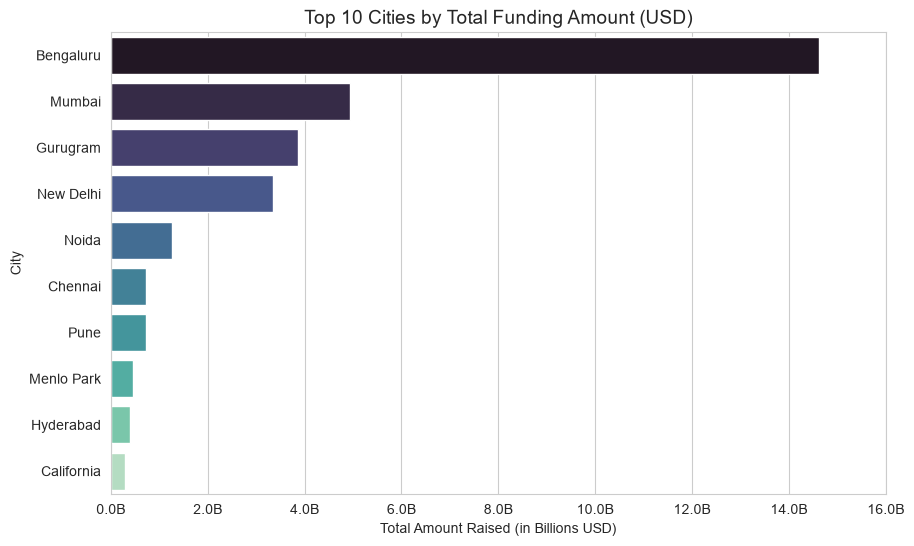

In [32]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_cities_amount_plot.values, y=top_cities_amount_plot.index, hue=top_cities_amount_plot.index, palette='mako', legend=False)
plt.title('Top 10 Cities by Total Funding Amount (USD)', fontsize=14)
plt.xlabel('Total Amount Raised (in Billions USD)')
plt.ylabel('City')
plt.xticks(ticks=plt.xticks()[0], labels=[f'{x/1e9:.1f}B' for x in plt.xticks()[0]])
plt.show()

In [33]:
df['Year'] = df['Date dd/mm/yyyy'].dt.year
yearly_funding = df.groupby('Year')['Amount in USD'].sum()
yearly_funding

Year
2015    8.601187e+09
2016    3.828089e+09
2017    1.042931e+10
2018    5.122368e+09
2019    5.800919e+09
2020    3.902073e+08
Name: Amount in USD, dtype: float64

In [34]:
df.groupby('Year')['Date dd/mm/yyyy'].agg(['min', 'max', 'count'])

,min,max,count
Year,,,
2015,2015-01-02,2015-12-30,936
2016,2016-01-01,2016-12-30,993
2017,2017-01-02,2017-12-27,687
2018,2018-01-02,2018-12-06,310
2019,2019-01-03,2019-12-20,111
2020,2020-01-02,2020-01-13,7


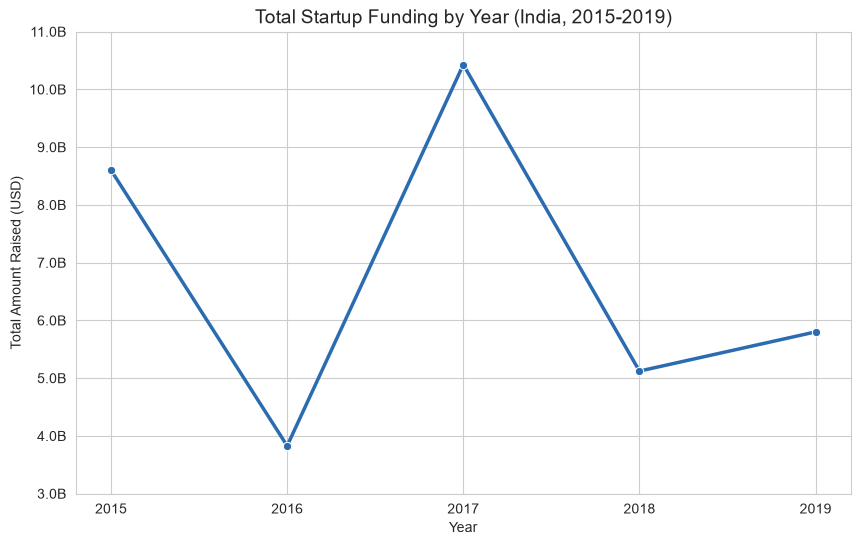

In [35]:
yearly_funding_clean = yearly_funding.drop(2020)

plt.figure(figsize=(10, 6))
sns.lineplot(x=yearly_funding_clean.index, y=yearly_funding_clean.values, marker='o', linewidth=2.5, color='#2b6cb0')
plt.title('Total Startup Funding by Year (India, 2015-2019)', fontsize=14)
plt.xlabel('Year')
plt.ylabel('Total Amount Raised (USD)')
plt.xticks(yearly_funding_clean.index)
plt.ticklabel_format(style='plain', axis='y')
plt.yticks(ticks=plt.yticks()[0], labels=[f'{y/1e9:.1f}B' for y in plt.yticks()[0]])
plt.show()

In [36]:
yearly_stats = df.groupby('Year').agg(
    total_funding=('Amount in USD', 'sum'),
    deal_count=('Amount in USD', 'count'),
    avg_deal_size=('Amount in USD', 'mean')
)
yearly_stats = yearly_stats.drop(2020)  # excluding partial year, same reasoning as before
yearly_stats

,total_funding,deal_count,avg_deal_size
Year,,,
2015,8.601187e+09,647,1.329395e+07
2016,3.828089e+09,586,6.532574e+06
2017,1.042931e+10,456,2.287129e+07
2018,5.122368e+09,265,1.932969e+07
2019,5.800919e+09,104,5.577806e+07


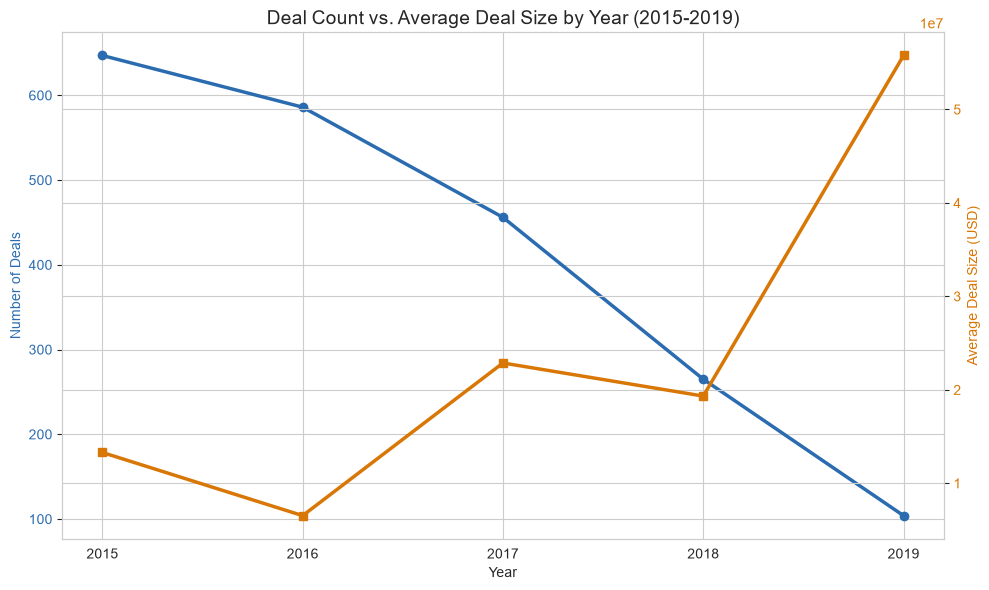

In [37]:
fig, ax1 = plt.subplots(figsize=(10, 6))

color1 = '#2b6cb0'
ax1.set_xlabel('Year')
ax1.set_xticks(yearly_stats.index)
ax1.set_ylabel('Number of Deals', color=color1)
ax1.plot(yearly_stats.index, yearly_stats['deal_count'], marker='o', color=color1, linewidth=2.5, label='Deal Count')
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()
color2 = '#d97706'
ax2.set_ylabel('Average Deal Size (USD)', color=color2)
ax2.plot(yearly_stats.index, yearly_stats['avg_deal_size'], marker='s', color=color2, linewidth=2.5, label='Avg Deal Size')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Deal Count vs. Average Deal Size by Year (2015-2019)', fontsize=14)
fig.tight_layout()
plt.show()

### Insight: Indian Startup Funding Market Matured 2015-2019
- Deal count declined steadily every year (647 → 104), while average deal size grew (~$13M → ~$56M)
- 2017's funding peak ($10.4B total) was driven by fewer, larger deals (avg $22.9M) — not more startups getting funded
- Interpretation: investors shifted from spreading many small early-stage checks toward concentrating capital in fewer, larger, likely lower-risk bets — a sign of a maturing market
- 2020 data excluded from all year-based analysis (only 7 deals covering Jan 2-13, incomplete year)

In [38]:
df['Industry Vertical'].value_counts().head(15)

Industry Vertical
Consumer Internet    941
Technology           478
eCommerce            186
Unknown              171
Healthcare            70
Finance               62
ECommerce             61
Logistics             32
E-Commerce            29
Education             24
Food & Beverage       23
Ed-Tech               14
E-commerce            12
FinTech                9
Ecommerce              8
Name: count, dtype: int64

In [39]:
industry_map = {
    'eCommerce': 'E-Commerce',
    'ECommerce': 'E-Commerce',
    'E-commerce': 'E-Commerce',
    'Ecommerce': 'E-Commerce',
}
df['Industry Vertical'] = df['Industry Vertical'].replace(industry_map)

df['Industry Vertical'].value_counts().head(15)

Industry Vertical
Consumer Internet    941
Technology           478
E-Commerce           296
Unknown              171
Healthcare            70
Finance               62
Logistics             32
Education             24
Food & Beverage       23
Ed-Tech               14
FinTech                9
IT                     8
Food and Beverage      6
Real Estate            6
Fin-Tech               6
Name: count, dtype: int64

In [40]:
industry_map_2 = {
    'Food and Beverage': 'Food & Beverage',
    'Fin-Tech': 'FinTech',
}
df['Industry Vertical'] = df['Industry Vertical'].replace(industry_map_2)

df['Industry Vertical'].value_counts().head(15)

Industry Vertical
Consumer Internet      941
Technology             478
E-Commerce             296
Unknown                171
Healthcare              70
Finance                 62
Logistics               32
Food & Beverage         29
Education               24
FinTech                 15
Ed-Tech                 14
IT                       8
Real Estate              6
Others                   6
Health and Wellness      5
Name: count, dtype: int64

In [41]:
df['Industry Vertical'].value_counts().tail(30)

Industry Vertical
Beauty & Wellness Mobile App                   1
Material Collection & Recycling                1
Online Pharmacy & Drug DB                      1
Online / Mobile Customer Support               1
Online Classifieds & Listings                  1
Fashion ECommerce                              1
Private Coaching Centers                       1
Online Certification Courses                   1
Ethnic Product eCommerce                       1
Last Minute Travel Deals mobile marketplace    1
usiness expense management                     1
Auto Rickshaw based Logistics                  1
Restaurant reservation app                     1
Spam Call block App                            1
Online Insurance Aggregator                    1
Restaurant Management Platform                 1
Food Logistics & Delivery                      1
Interactive Educational Games                  1
Clean Tech                                     1
Grey collar Job Board                          1
On

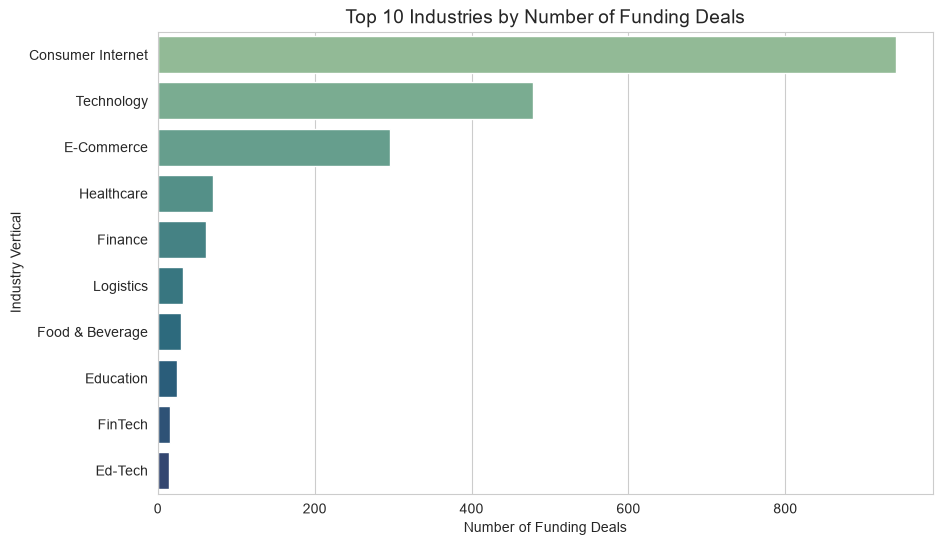

In [42]:
top_industries = df[df['Industry Vertical'] != 'Unknown']['Industry Vertical'].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_industries.values, y=top_industries.index, hue=top_industries.index, palette='crest', legend=False)
plt.title('Top 10 Industries by Number of Funding Deals', fontsize=14)
plt.xlabel('Number of Funding Deals')
plt.ylabel('Industry Vertical')
plt.show()

In [43]:
top_industries_amount = df[df['Industry Vertical'] != 'Unknown'].groupby('Industry Vertical')['Amount in USD'].sum().sort_values(ascending=False).head(10)
top_industries_amount

Industry Vertical
E-Commerce                            8.258656e+09
Consumer Internet                     6.253084e+09
Technology                            2.229708e+09
Finance                               1.971438e+09
FinTech                               1.361411e+09
Online Marketplace                    7.001430e+08
E-Commerce & M-Commerce platform      6.800000e+08
B2B                                   5.870000e+08
Car Aggregator & Retail Mobile App    5.000000e+08
Ecommerce Marketplace                 5.000000e+08
Name: Amount in USD, dtype: float64

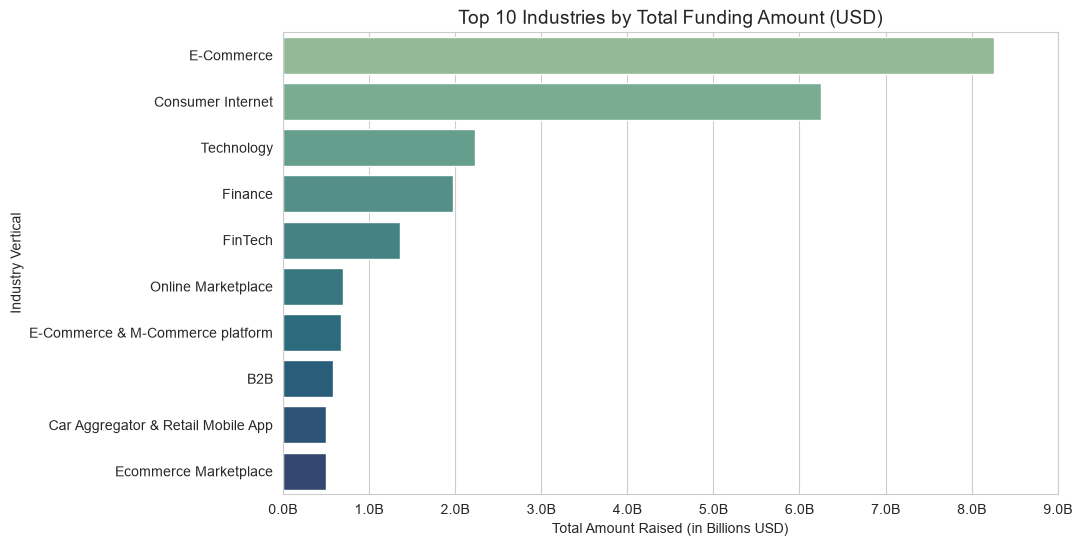

In [44]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_industries_amount.values, y=top_industries_amount.index, hue=top_industries_amount.index, palette='crest', legend=False)
plt.title('Top 10 Industries by Total Funding Amount (USD)', fontsize=14)
plt.xlabel('Total Amount Raised (in Billions USD)')
plt.ylabel('Industry Vertical')
plt.xticks(ticks=plt.xticks()[0], labels=[f'{x/1e9:.1f}B' for x in plt.xticks()[0]])
plt.show()

### Insight: Industry Cleaning + Deal Count vs. Total Funding

**Cleaning performed:**
- Standardized 5 spelling variants of E-Commerce (eCommerce, ECommerce, E-commerce, Ecommerce → E-Commerce)
- Merged Food and Beverage → Food & Beverage, and Fin-Tech → FinTech
- Kept Ed-Tech and Education as separate categories (related but not identical)
- Left highly specific one-off categories (e.g. "Online Pharmacy & Drug DB") and single-deal overlapping categories (e.g. "Online Marketplace") unmerged, to avoid making subjective category-boundary decisions that could bias the ranking

**Deal count vs. total funding — the ranking flips:**
| Rank | By Deal Count | By Total Funding |
|---|---|---|
| 1 | Consumer Internet (941 deals) | E-Commerce ($8.26B) |
| 2 | Technology (478 deals) | Consumer Internet ($6.25B) |
| 3 | E-Commerce (296 deals) | Technology ($2.23B) |

**Insight:** Consumer Internet leads by number of deals, but E-Commerce leads by total money raised — despite having less than a third as many deals. This means the average E-Commerce deal is significantly larger than the average Consumer Internet deal.

**Interpretation:** E-Commerce startups likely need larger capital injections to fund inventory, logistics, and warehousing, while Consumer Internet startups (apps, content platforms) typically require less capital to scale — so investors write bigger checks per deal in E-Commerce even though fewer such deals happen.

**Limitation:** Some categories in the raw data overlap in meaning (e.g. "Online Marketplace", "E-Commerce & M-Commerce platform") but were kept separate since each represented a single large deal, and merging them could artificially inflate E-Commerce's total based on a subjective boundary decision rather than a genuine spelling fix.

In [45]:
top_investors = df[df['Investors Name'] != 'Unknown']['Investors Name'].value_counts().head(10)
top_investors

Investors Name
Undisclosed Investors       39
Undisclosed investors       30
Ratan Tata                  25
Indian Angel Network        23
Kalaari Capital             16
Sequoia Capital             15
Group of Angel Investors    15
Accel Partners              12
Undisclosed Investor        12
Undisclosed                 11
Name: count, dtype: int64

In [46]:
undisclosed_variants = ['Undisclosed Investors', 'Undisclosed investors', 'Undisclosed Investor', 'Undisclosed']
df['Investors Name'] = df['Investors Name'].replace({v: 'Undisclosed' for v in undisclosed_variants})

# Now get top REAL investors, excluding both Unknown (missing) and Undisclosed (anonymized)
top_investors_real = df[~df['Investors Name'].isin(['Unknown', 'Undisclosed'])]['Investors Name'].value_counts().head(10)
top_investors_real

Investors Name
Ratan Tata                  25
Indian Angel Network        23
Kalaari Capital             16
Sequoia Capital             15
Group of Angel Investors    15
Accel Partners              12
Venture Catalysts           11
Brand Capital               11
undisclosed investors       11
SAIF Partners               10
Name: count, dtype: int64

In [47]:
df.loc[df['Investors Name'].str.lower() == 'undisclosed investors', 'Investors Name'] = 'Undisclosed'

top_investors_real = df[~df['Investors Name'].isin(['Unknown', 'Undisclosed'])]['Investors Name'].value_counts().head(10)
top_investors_real

Investors Name
Ratan Tata                  25
Indian Angel Network        23
Kalaari Capital             16
Sequoia Capital             15
Group of Angel Investors    15
Accel Partners              12
Venture Catalysts           11
Brand Capital               11
SAIF Partners               10
RoundGlass Partners         10
Name: count, dtype: int64

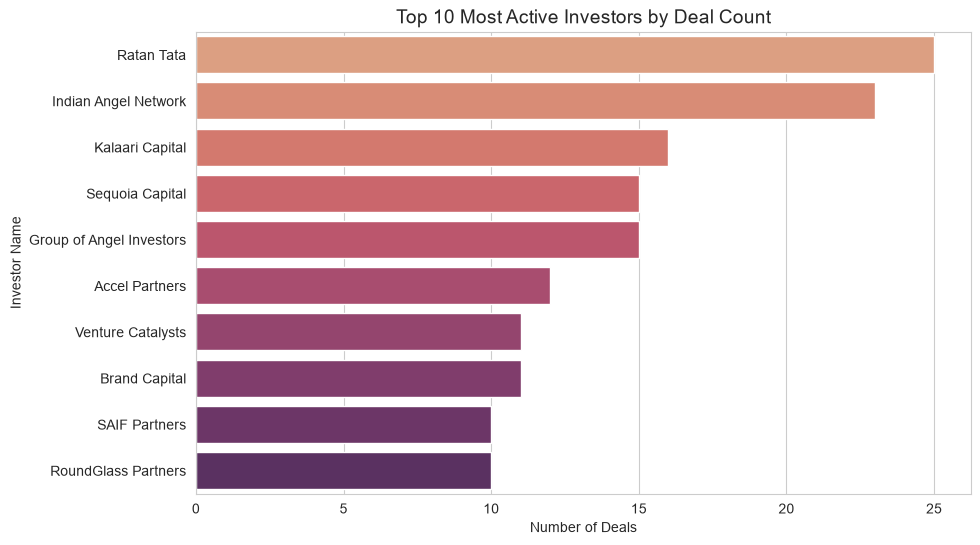

In [48]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_investors_real.values, y=top_investors_real.index, hue=top_investors_real.index, palette='flare', legend=False)
plt.title('Top 10 Most Active Investors by Deal Count', fontsize=14)
plt.xlabel('Number of Deals')
plt.ylabel('Investor Name')
plt.show()

### Insight: Most Active Investors (by Deal Count)

**Cleaning performed:**
- Merged multiple case/spelling variants of "undisclosed investors" (capitalized, lowercase, singular/plural) into one consistent 'Undisclosed' label
- Excluded both 'Unknown' (missing data) and 'Undisclosed' (intentionally anonymized) from the ranking — combined, 'Undisclosed' investor entries totaled over 100 rows, more than any single named investor, but represent a lack of disclosure, not a real investor

**Top investors:** Ratan Tata (25 deals) leads as the most active individual investor, ahead of institutional investors like Indian Angel Network (23) and Kalaari Capital (16).

**Limitation:** The Investors Name column often lists multiple co-investors in a single deal, separated by commas, without being split into individual rows. This chart counts raw frequency of how often a name appears in the text, not a true "exclusive deals led" count — a co-investor appearing alongside others in one deal is counted the same as an investor leading a deal solo. A deeper analysis would split multi-investor rows before counting, but this was out of scope for this pass given time constraints.

## Stage 3 Summary: Key Insights
1. **Geographic concentration**: Bengaluru dominates both deal count (~850) and total funding (~$14.6B), followed by Mumbai, Gurugram, and New Delhi. These 4 cities account for the vast majority of Indian startup funding activity.
2. **Activity ≠ Money (cities)**: Gurugram outranks New Delhi in total funding despite fewer deals — larger average deal sizes in Gurugram.
3. **Funding is volatile, not steadily growing (2015-2019)**: Peaked in 2017 ($10.4B) driven by fewer but bigger deals, not broader activity.
4. **Market maturation signal**: Deal count declined every year (647→104) while average deal size grew (~$13M→~$56M) — investors concentrating capital into fewer, larger bets over time.
5. **Activity ≠ Money (industries)**: Consumer Internet leads by deal count (941), but E-Commerce leads by total funding ($8.26B) — E-Commerce deals are larger on average, likely due to higher capital needs (inventory/logistics).
6. **Most active investor**: Ratan Tata (25 deals) — ahead of institutional players like Indian Angel Network and Kalaari Capital.